# Video Games Clustering

Clustering ~474K video games (RAWG dataset) using popularity, release year, platforms and genres.

**Pipeline:** clean → encode platforms/genres → log + scale → choose k → KMeans → profile clusters → PCA plot → compare with Hierarchical and DBSCAN.

**Requirements:** Python 3, `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`. Place `game_info.csv` in the same folder as this notebook.

## 1. Imports

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

## 2. Load and clean the data
Drop columns that are mostly empty or are identifiers, and turn the release date into a year.

In [13]:
df = pd.read_csv('game_info.csv')
print('Raw shape:', df.shape)

df = df.drop(columns=['slug', 'website', 'metacritic', 'publishers',
                      'esrb_rating', 'tba', 'updated'])

df['released'] = pd.to_datetime(df['released'], errors='coerce')
df['release_year'] = df['released'].dt.year
df['release_year'] = df['release_year'].fillna(df['release_year'].median())  # missing year -> median
df = df.drop(columns=['released'])

Raw shape: (474417, 27)


## 3. Encode platforms and genres
Each of the top platforms / genres becomes a 0/1 column. Games with no genre are labeled `Unknown`.

In [14]:
# Platforms: top 12
platforms = df['platforms'].fillna('').str.replace('||', ',', regex=False)
plat_dummies = platforms.str.get_dummies(sep=',').drop(columns='', errors='ignore')
plat_dummies = plat_dummies[plat_dummies.sum().nlargest(12).index].add_prefix('plat_')
df = df.join(plat_dummies)
platform_cols = list(plat_dummies.columns)

# Genres: top 15
genres = df['genres'].fillna('Unknown').str.replace('||', ',', regex=False)
genre_dummies = genres.str.get_dummies(sep=',')
genre_dummies = genre_dummies[genre_dummies.sum().nlargest(15).index].add_prefix('genre_')
df = df.join(genre_dummies)
genre_cols = list(genre_dummies.columns)

print(len(platform_cols), 'platform columns,', len(genre_cols), 'genre columns')

12 platform columns, 15 genre columns


## 4. Build the feature matrix
Count-like columns are heavily skewed, so we apply `log1p`, then standardize every feature.

In [31]:
skewed = ['playtime', 'achievements_count', 'ratings_count', 'suggestions_count',
          'game_series_count', 'reviews_count', 'added_status_yet', 'added_status_owned',
          'added_status_beaten', 'added_status_toplay', 'added_status_dropped',
          'added_status_playing']
num_cols = ['rating', 'rating_top', 'release_year'] + skewed

feature_cols = num_cols + genre_cols + platform_cols
X = df[feature_cols].copy()

X[skewed] = np.log1p(X[skewed])
X = X.fillna(X.median())
X_scaled = StandardScaler().fit_transform(X)

print(X_scaled.shape)

(474417, 42)


## 5. Choose the number of clusters (k)
Elbow and silhouette on a random sample of 100K games (for speed).

2 0.678
3 0.209
4 0.165
5 0.08
6 0.159
7 0.109
8 0.086


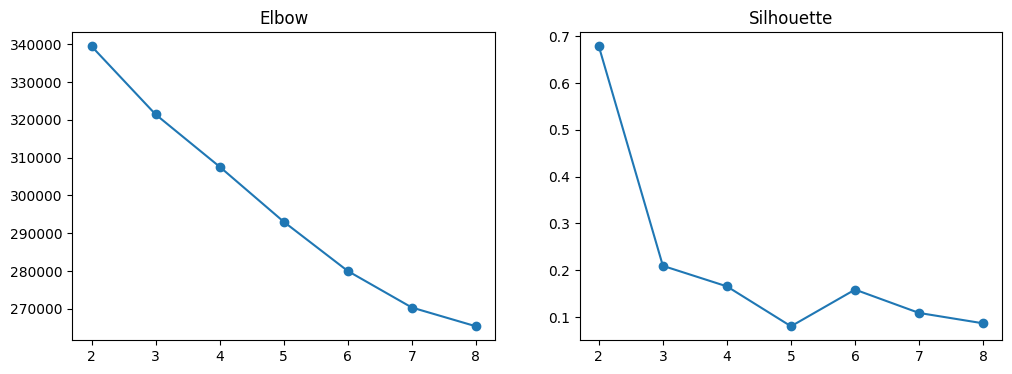

In [32]:
rng = np.random.RandomState(42)
k_idx = rng.choice(len(X_scaled), min(len(X_scaled), 10000), replace=False)
X_k = X_scaled[k_idx]

ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=3).fit(X_k)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_k, km.labels_, sample_size=min(len(X_k), 5000), random_state=42))
    print(k, round(sils[-1], 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker='o')
ax[0].set_title('Elbow')
ax[1].plot(ks, sils, marker='o')
ax[1].set_title('Silhouette')
plt.show()

**Choice:** we pick the k with the highest silhouette score. k = 2 scores far higher than any other k (the others are around 0.2 or lower), and the elbow curve has no clear bend, so the silhouette decides.

## 6. KMeans (best k)

In [33]:
best_k = list(ks)[int(np.argmax(sils))]
print('Best k by silhouette:', best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

df['cluster'].value_counts()

Best k by silhouette: 2


,count
cluster,
0,461874
1,12543


## 7. Cluster profiles

In [34]:
# Average raw value of each feature per cluster
profile = df.groupby('cluster')[feature_cols].mean().T
profile

cluster,0,1
rating,0.001011,3.205110
rating_top,0.005846,3.522762
release_year,2017.156463,2010.637567
playtime,0.131724,3.533445
achievements_count,3.355264,44.717771
ratings_count,0.093891,77.577533
suggestions_count,84.697647,368.341784
game_series_count,0.009903,1.310213
reviews_count,0.096615,78.245794
added_status_yet,0.049048,24.103962


In [35]:
Z = pd.DataFrame(X_scaled, columns=feature_cols, index=df.index)
Z['cluster'] = df['cluster']
means = Z.groupby('cluster').mean().T

for c in means.columns:
    s = means[c].sort_values(ascending=False)
    print(f'\ncluster {c} - highest:', s.head(5).round(2).to_dict())
    print(f'cluster {c} - lowest:', s.tail(5).round(2).to_dict())


cluster 0 - highest: {'release_year': 0.04, 'plat_Web': 0.01, 'genre_Unknown': 0.01, 'genre_Platformer': 0.01, 'genre_Puzzle': 0.0}
cluster 0 - lowest: {'added_status_dropped': -0.13, 'reviews_count': -0.14, 'ratings_count': -0.14, 'rating_top': -0.15, 'rating': -0.16}

cluster 1 - highest: {'rating': 5.72, 'rating_top': 5.59, 'ratings_count': 5.21, 'reviews_count': 5.21, 'added_status_dropped': 4.96}
cluster 1 - lowest: {'genre_Puzzle': -0.17, 'genre_Platformer': -0.19, 'genre_Unknown': -0.42, 'plat_Web': -0.54, 'release_year': -1.4}


\**Interpretation**
- **Large cluster**: regular games with low popularity (few ratings, reviews and owners).
- **Small cluster**: very popular, highly rated and widely owned games, on many platforms, mostly older releases.

## 8. PCA visualization
PCA is used only to draw the clusters in 2D. It was not used for the clustering itself.

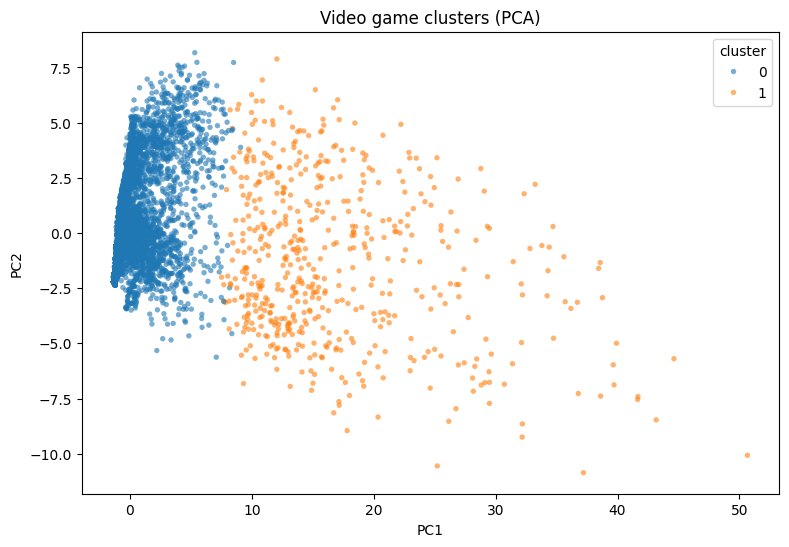

Explained variance: 0.295


In [36]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({'PC1': coords[:, 0],
                        'PC2': coords[:, 1],
                        'cluster': df['cluster'].values}).sample(min(len(df), 20000), random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue='cluster',
                palette='tab10', s=15, alpha=0.6, linewidth=0)
plt.title('Video game clusters (PCA)')
plt.show()

print('Explained variance:', pca.explained_variance_ratio_.sum().round(3))

The first two components explain only ~30% of the variance, so this plot is only a rough view.
The games form a continuous spread (mainly by popularity), so the groups are not clearly separated.

---
## 9. Other algorithms: Hierarchical clustering
Hierarchical clustering needs an N×N distance matrix, so we run it on a random sample of 10,000 games, using the same k as KMeans.

In [21]:
h_idx = np.random.RandomState(42).choice(len(X_scaled), 10000, replace=False)
X_h = X_scaled[h_idx]

hc = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit(X_h)

print('Hierarchical silhouette:', round(silhouette_score(X_h, hc.labels_), 3))
print(pd.Series(hc.labels_).value_counts())

Hierarchical silhouette: 0.664
0    9741
1     259
Name: count, dtype: int64


Compare the silhouette and cluster sizes with KMeans: a similar split supports the KMeans result.

---
## 10. Other algorithms: DBSCAN
Also run on a 10,000-game sample. Label `-1` means noise. The silhouette is computed without the noise points.

In [22]:
d_idx = np.random.RandomState(42).choice(len(X_scaled), 10000, replace=False)
X_d = X_scaled[d_idx]

db = DBSCAN(eps=3, min_samples=20).fit(X_d)
labels = db.labels_

print('Clusters found:', len(set(labels) - {-1}), '| noise points:', (labels == -1).sum())
print(pd.Series(labels).value_counts().head(10))

mask = labels != -1
if len(set(labels[mask])) > 1:
    print('DBSCAN silhouette (no noise):', round(silhouette_score(X_d[mask], labels[mask]), 3))

Clusters found: 40 | noise points: 1804
 0     3307
-1     1804
 7      754
 9      730
 8      481
 13     367
 2      326
 1      297
 16     264
 6      205
Name: count, dtype: int64
DBSCAN silhouette (no noise): 0.305


DBSCAN finds about 40 small clusters and marks about 18% of the games as noise, so it does not give a clean split of this data.

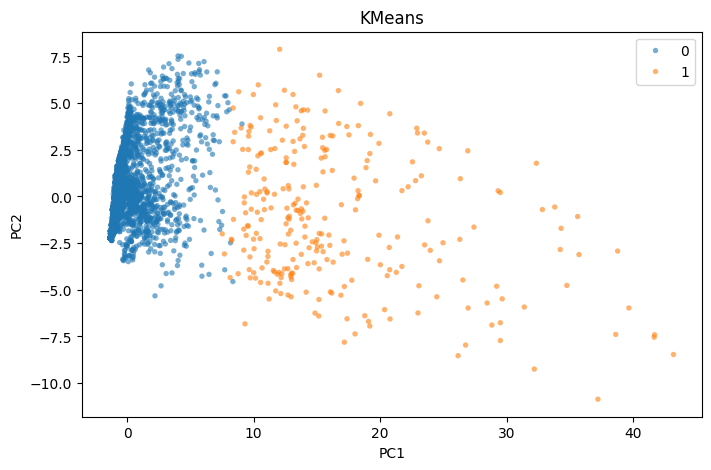

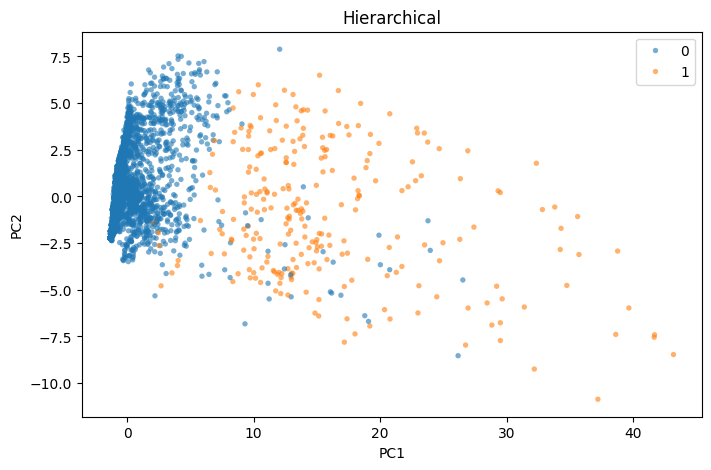

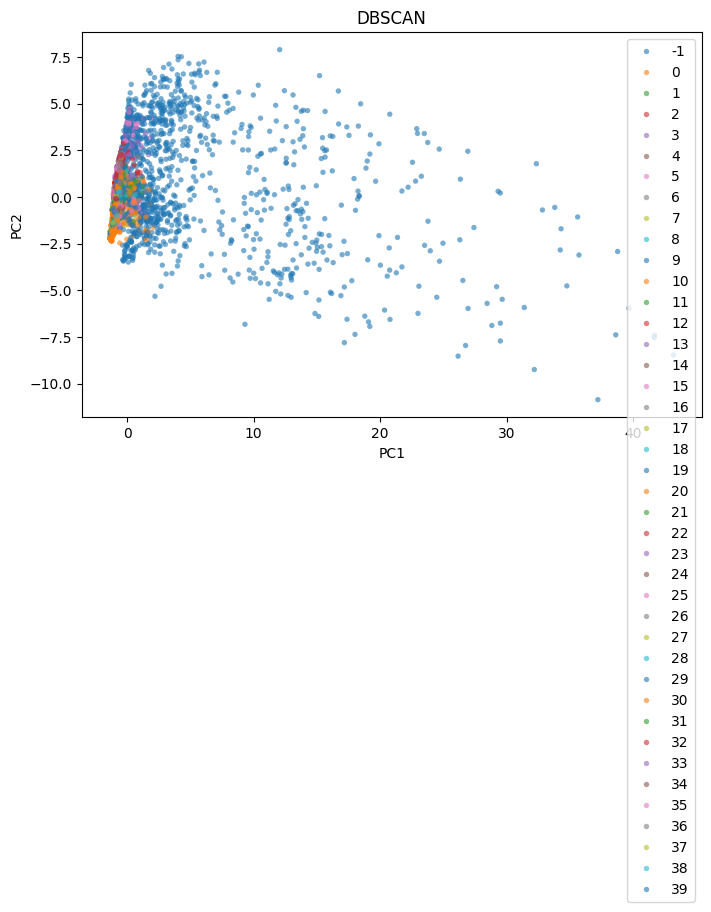

In [37]:
def plot_clusters(points, labels, title):
    plt.figure(figsize=(8, 5))
    sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=labels,
                    palette='tab10', s=15, alpha=0.6, linewidth=0, legend='full')
    plt.title(title)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()

# kmeans
k_plot = np.random.RandomState(42).choice(len(df), 10000, replace=False)
plot_clusters(coords[k_plot], df['cluster'].values[k_plot], 'KMeans')

# Hierarchical
plot_clusters(coords[h_idx], hc.labels_, 'Hierarchical')

# DBSCAN (-1 = noise)
plot_clusters(coords[d_idx], labels, 'DBSCAN')

## 11. Conclusion

| Method | Result |
|---|---|
| KMeans (best k by silhouette) | Highest silhouette at k = 2; separates very popular games from the rest |
| Hierarchical (same k, 10K sample) | Compare with KMeans: a similar split supports the result |
| DBSCAN (10K sample) | About 40 small clusters and 18% noise; silhouette (0.305) excludes the noise |

The data is a continuous spread rather than separate groups, so the clusters mainly separate the very popular games from the rest.
**KMeans with k chosen by silhouette** is the simplest and most useful result.